# Heartbeat PCG Classification -- FINAL Model & Evaluation Notebook

This is the final, consolidated notebook for the project's chosen
architecture: a weighted ensemble of a frozen-YAMNet classifier head and
a from-scratch deep CNN, with the ensemble weight chosen automatically
via validation performance (never by hand, never by peeking at test data).

**Works with either dataset version** -- just upload whichever zip you
want to test (original 50%-overlap chunking, or the re-chunked v3 with
higher Extra_Systole overlap). Nothing in the code needs to change
between them; set `DATASET_LABEL` below purely so your printed summaries
say which version you ran.

**Sections:**
1. Setup (GPU, data, modules)
2. Model A: YAMNet + classifier head
3. Model B: Deep CNN
4. Ensemble with automatic, validation-based weight selection
5. Final honest test evaluation
6. Save everything (both models + chosen weight)
7. (Optional, expensive) Grouped 5-fold cross-validation of the final architecture

## 0. Check GPU

In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Get your data into Colab

Set `DATASET_LABEL` to describe whichever zip you're about to upload --
this is just for your own record-keeping in the printed summaries below,
it doesn't change any code path.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
DATASET_LABEL = "Original"  # or "rechunked_v3" -- edit before running

In [5]:
'''from google.colab import files
uploaded = files.upload()
ZIP_NAME = list(uploaded.keys())[0]
print("Uploaded:", ZIP_NAME)'''

'from google.colab import files\nuploaded = files.upload()\nZIP_NAME = list(uploaded.keys())[0]\nprint("Uploaded:", ZIP_NAME)'

In [6]:
ZIP_NAME = "/content/drive/MyDrive/heart_project/heart_project_data.zip"  # adjust path

In [7]:
import zipfile, os

EXTRACT_DIR = "/content/heart_project"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_NAME, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

found = False
for root, dirs, files_ in os.walk(EXTRACT_DIR):
    if 'split_dataset' in dirs and 'noise_clips' in dirs:
        os.chdir(root)
        found = True
        break

if not found:
    print("WARNING: could not find split_dataset/ and noise_clips/ together.")
else:
    print(f"Dataset: {DATASET_LABEL}")
    print("Working directory:", os.getcwd())
    print("Contents:", os.listdir())

Dataset: Original
Working directory: /content/heart_project/heart_project_data
Contents: ['split_dataset', 'noise_clips']


## 2. Write the shared utility modules

In [8]:
%%writefile spectrogram_utils.py
import numpy as np
import librosa
from scipy.signal import butter, sosfiltfilt

# --- SHARED CONFIG -- keep everything in the project pointed at this file ---
TARGET_SR = 16000
CHUNK_DURATION = 3          # seconds, matches step 1 chunking
N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 64
FMAX = 800                  # PCG diagnostic content lives under ~600-800Hz

EXPECTED_SAMPLES = TARGET_SR * CHUNK_DURATION
N_FRAMES = 1 + EXPECTED_SAMPLES // HOP_LENGTH

# Heart sound diagnostic content lives in ~20-800Hz. Filtering this
# consistently on EVERY signal (real chunks AND noise clips, before any
# augmentation) removes clearly out-of-band noise/hiss/drift for free.
# It does NOT remove noise that overlaps this band (voices, rumble, fabric
# rustle) -- that's what noise-mixing augmentation is for. The two are
# complementary, not redundant.
BANDPASS_LOW_HZ = 20
BANDPASS_HIGH_HZ = 800
BANDPASS_ORDER = 4

_bandpass_sos_cache = {}

# --- Despike settings ---
# Targets isolated, single-sample-to-a-few-sample digital glitches (an
# instantaneous jump to near full-scale with quiet neighbors on both
# sides) -- distinct from genuine sustained loud/clipped audio, which
# spans many consecutive samples with a smooth attack/decay and is left
# untouched.
DESPIKE_THRESHOLD = 0.95      # near full-scale, in normalized [-1, 1] units
DESPIKE_MAX_RUN = 3           # longer runs are treated as real loud audio
DESPIKE_NEIGHBOR_QUIET = 0.3  # immediate neighbors must be well below this


def despike_glitches(y):
    """Removes isolated near-full-scale digital glitches via linear
    interpolation across the glitch, using its immediate neighbors."""
    y = y.copy()
    abs_y = np.abs(y)
    candidates = np.where(abs_y >= DESPIKE_THRESHOLD)[0]
    if len(candidates) == 0:
        return y

    groups = [[candidates[0]]]
    for idx in candidates[1:]:
        if idx - groups[-1][-1] <= 2:
            groups[-1].append(idx)
        else:
            groups.append([idx])

    for group in groups:
        if len(group) > DESPIKE_MAX_RUN:
            continue  # sustained loud region -- real audio, leave it

        start, end = group[0], group[-1]
        left, right = start - 1, end + 1
        if left < 0 or right >= len(y):
            continue

        # Only treat as a glitch if the audio was genuinely quiet right
        # before and after it -- a real transient's neighbors are still
        # elevated, not near-baseline.
        if abs_y[left] < DESPIKE_NEIGHBOR_QUIET and abs_y[right] < DESPIKE_NEIGHBOR_QUIET:
            y[left:right + 1] = np.linspace(y[left], y[right], right - left + 1)

    return y


def get_bandpass_sos(sr=TARGET_SR):
    """Cached filter coefficients -- avoids recomputing per-call."""
    if sr not in _bandpass_sos_cache:
        nyquist = sr / 2
        low = BANDPASS_LOW_HZ / nyquist
        high = min(BANDPASS_HIGH_HZ / nyquist, 0.99)
        _bandpass_sos_cache[sr] = butter(BANDPASS_ORDER, [low, high],
                                         btype='band', output='sos')
    return _bandpass_sos_cache[sr]


def apply_bandpass(y, sr=TARGET_SR):
    """Zero-phase band-pass filter, applied identically to real audio and
    noise clips alike, so nothing in the pipeline sees unfiltered content."""
    sos = get_bandpass_sos(sr)
    return sosfiltfilt(sos, y).astype(np.float32)


def load_and_filter(filepath, sr=TARGET_SR):
    """The ONE function that should load audio from disk anywhere in this
    project -- loading, resampling, despiking, and band-pass filtering
    all happen here, so training data, noise clips, and visualizations
    can never silently diverge in how they're preprocessed."""
    y, _ = librosa.load(filepath, sr=sr)
    y = despike_glitches(y)       # remove isolated digital glitches first
    return apply_bandpass(y, sr)  # then band-limit to the diagnostic range


def load_fixed_length(source, sr=TARGET_SR, is_array=False):
    """Loads audio (from filepath or an existing array) and forces it to
    exactly CHUNK_DURATION seconds. Re-run this after any augmentation
    that could change length (e.g. time-stretch). Filepath inputs are
    band-pass filtered via load_and_filter; array inputs are assumed to
    already be filtered (e.g. augmented audio that started from a
    filtered source)."""
    if is_array:
        y = source
    else:
        y = load_and_filter(source, sr)

    if len(y) > EXPECTED_SAMPLES:
        y = y[:EXPECTED_SAMPLES]
    elif len(y) < EXPECTED_SAMPLES:
        y = np.pad(y, (0, EXPECTED_SAMPLES - len(y)), mode='constant')
    return y


def audio_to_logmel(y, sr=TARGET_SR):
    """Converts a fixed-length audio array into a fixed-shape log-mel
    spectrogram: (N_MELS, N_FRAMES)."""
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmax=FMAX
    )
    S_dB = librosa.power_to_db(S, ref=np.max)

    if S_dB.shape[1] > N_FRAMES:
        S_dB = S_dB[:, :N_FRAMES]
    elif S_dB.shape[1] < N_FRAMES:
        pad_width = N_FRAMES - S_dB.shape[1]
        S_dB = np.pad(S_dB, ((0, 0), (0, pad_width)), mode='constant',
                      constant_values=S_dB.min())

    return S_dB.astype(np.float32)


def wav_to_logmel(filepath):
    """Convenience wrapper: filepath -> fixed-shape log-mel spectrogram."""
    y = load_fixed_length(filepath)
    return audio_to_logmel(y, TARGET_SR)


Writing spectrogram_utils.py


In [9]:
%%writefile augmentation_utils.py
import os
import glob
import random
import numpy as np
import librosa

from spectrogram_utils import TARGET_SR, apply_bandpass, despike_glitches

# Probabilities are applied to EVERY sample identically, regardless of
# class label. This is what structurally prevents "amount of augmentation"
# from becoming a shortcut the model can use instead of real PCG features.
SAFE_AUG_PROB = 0.5     # chance of a generic transform (stretch/volume/faint noise)
NOISE_PROB = 0.3        # chance of real recorded ESP32 noise, independent of the above
SNR_DB_RANGE = (10, 20)

# Pitch-shifting changes the exact frequency band that defines a murmur --
# left out of the default rotation for that reason.
USE_PITCH_SHIFT = False
PITCH_SHIFT_STEPS = 1

_noise_pool_cache = None


def add_faint_noise(y):
    noise = np.random.normal(0, 0.005 * np.amax(np.abs(y)), len(y))
    return y + noise


def fix_length(y, target_length):
    if len(y) > target_length:
        return y[:target_length]
    elif len(y) < target_length:
        return np.pad(y, (0, target_length - len(y)), mode='constant')
    return y


def safe_augment(y, sr):
    """One randomly chosen generic transform -- never real recorded noise."""
    target_length = len(y)
    methods = ["stretch", "volume", "faint_noise"]
    if USE_PITCH_SHIFT:
        methods.append("pitch")
    method = random.choice(methods)

    if method == "stretch":
        rate = np.random.uniform(0.93, 1.07)
        return fix_length(librosa.effects.time_stretch(y, rate=rate), target_length)
    elif method == "volume":
        scale = np.random.uniform(0.7, 1.3)
        return np.clip(y * scale, -1.0, 1.0)
    elif method == "faint_noise":
        return add_faint_noise(y)
    else:
        return librosa.effects.pitch_shift(y, sr=sr, n_steps=PITCH_SHIFT_STEPS)


def load_noise_pool(noise_dir="noise_clips", target_sr=TARGET_SR):
    """Loads and caches your recorded ESP32 noise clips into one pool."""
    global _noise_pool_cache
    if _noise_pool_cache is not None:
        return _noise_pool_cache

    files = glob.glob(os.path.join(noise_dir, "*.wav"))
    if not files:
        return None

    pool = [apply_bandpass(despike_glitches(librosa.load(f, sr=target_sr, mono=True)[0]), target_sr)
            for f in files]
    _noise_pool_cache = np.concatenate(pool)
    return _noise_pool_cache


def get_noise_segment(noise_pool, num_samples):
    if len(noise_pool) < num_samples:
        repeats = int(np.ceil(num_samples / len(noise_pool)))
        noise_pool = np.tile(noise_pool, repeats)
    start = np.random.randint(0, len(noise_pool) - num_samples + 1)
    return noise_pool[start:start + num_samples]


def mix_at_snr(signal, noise, snr_db):
    signal_power = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)
    if noise_power == 0:
        return signal
    target_noise_power = signal_power / (10 ** (snr_db / 10))
    scale = np.sqrt(target_noise_power / noise_power)
    mixed = signal + noise * scale
    max_val = np.max(np.abs(mixed))
    if max_val > 1.0:
        mixed = mixed / max_val
    return mixed


def apply_random_augmentation(y, sr, noise_pool=None):
    """The ONE function used everywhere augmentation happens -- training
    generator and visualizations both call this, so behavior can never
    silently diverge between what you see and what the model trains on."""
    if random.random() < SAFE_AUG_PROB:
        y = safe_augment(y, sr)
    if noise_pool is not None and random.random() < NOISE_PROB:
        snr_db = np.random.uniform(*SNR_DB_RANGE)
        noise_seg = get_noise_segment(noise_pool, len(y))
        y = mix_at_snr(y, noise_seg, snr_db)
    return y


Writing augmentation_utils.py


In [10]:
%%writefile train_data_generator.py
import os
import numpy as np
import librosa
from tensorflow.keras.utils import Sequence

from spectrogram_utils import TARGET_SR, load_and_filter, load_fixed_length, audio_to_logmel
from augmentation_utils import apply_random_augmentation, load_noise_pool

TRAIN_DIR = "split_dataset/train"      # raw, unbalanced, unaugmented on disk
CLASSES = ["Normal", "Murmur", "Extra_Systole", "Artifact"]


class PCGSequence(Sequence):
    """Yields (spectrogram_batch, label_batch). With augment=True, every
    sample -- regardless of class -- has the same chance of being time
    -stretched, volume-jittered, or noise-mixed. Nothing here branches on
    class label, by design."""

    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:
                              (batch_idx + 1) * self.batch_size]
        X, y = [], []

        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)

            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                # time-stretch can change length -- re-fix before spectrogram
                audio = load_fixed_length(audio, is_array=True)

            spec = audio_to_logmel(audio, TARGET_SR)
            X.append(spec)
            y.append(label)

        X = np.array(X, dtype=np.float32)[..., np.newaxis]
        y = np.array(y, dtype=np.int64)
        return X, y


def compute_class_weights():
    """Since the train split on disk is NOT balanced (we balance via
    class_weight instead of file duplication), pass this dict to
    model.fit(..., class_weight=...)."""
    from sklearn.utils.class_weight import compute_class_weight

    labels = []
    for idx, cls in enumerate(CLASSES):
        class_dir = os.path.join(TRAIN_DIR, cls)
        n = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
        labels += [idx] * n

    labels = np.array(labels)
    weights = compute_class_weight(class_weight="balanced",
                                    classes=np.arange(len(CLASSES)), y=labels)
    return {i: w for i, w in enumerate(weights)}


if __name__ == "__main__":
    # Quick sanity check
    seq = PCGSequence(batch_size=8, augment=True)
    X, y = seq[0]
    print(f"Batch shape: {X.shape}, labels: {y}")
    print(f"Class weights: {compute_class_weights()}")


Writing train_data_generator.py


## 3. Import modules and sanity-check

In [11]:
from spectrogram_utils import (N_MELS, N_FRAMES, TARGET_SR, load_and_filter,
                               load_fixed_length, audio_to_logmel, wav_to_logmel, FMAX)
from augmentation_utils import apply_random_augmentation, load_noise_pool
from train_data_generator import PCGSequence, compute_class_weights, CLASSES, TRAIN_DIR

sanity_gen = PCGSequence(batch_size=8, augment=True)
X_batch, y_batch = sanity_gen[0]
print("Batch shape:", X_batch.shape)
print("Labels in batch:", y_batch)

Batch shape: (8, 64, 188, 1)
Labels in batch: [0 2 1 1 0 1 0 3]


## 4. Dataset summary

In [12]:
def count_wavs(split_dir):
    counts = {}
    for cls in CLASSES:
        class_dir = os.path.join(split_dir, cls)
        counts[cls] = len([f for f in os.listdir(class_dir) if f.endswith(".wav")]) if os.path.isdir(class_dir) else 0
    return counts

train_counts = count_wavs("split_dataset/train")
val_counts = count_wavs("split_dataset/val")
test_counts = count_wavs("split_dataset/test")

print(f"Dataset: {DATASET_LABEL}")
print(f"{'Class':<15}{'Train':>8}{'Val':>8}{'Test':>8}")
for cls in CLASSES:
    print(f"{cls:<15}{train_counts[cls]:>8}{val_counts[cls]:>8}{test_counts[cls]:>8}")
print(f"\nTotal train: {sum(train_counts.values())}, val: {sum(val_counts.values())}, test: {sum(test_counts.values())}")

Dataset: Original
Class             Train     Val    Test
Normal              893     184     242
Murmur              429      93      84
Extra_Systole       109      29      16
Artifact            168      36      36

Total train: 1599, val: 342, test: 378


## 5. Model A -- Load YAMNet (frozen feature extractor)

In [13]:
import tensorflow_hub as hub

yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')

sample_path = os.path.join(TRAIN_DIR, "Normal", sorted(os.listdir(os.path.join(TRAIN_DIR, "Normal")))[0])
sample_audio = load_and_filter(sample_path, TARGET_SR)
sample_audio = load_fixed_length(sample_audio, is_array=True)
waveform = tf.convert_to_tensor(sample_audio, dtype=tf.float32)
scores, embeddings, spectrogram = yamnet_model(waveform)
print("Embeddings shape (num_frames, 1024):", embeddings.shape)

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Embeddings shape (num_frames, 1024): (6, 1024)


## 6. Model A -- training generator (mean-pooled YAMNet embeddings, on-the-fly augmented)

In [14]:
from tensorflow.keras.utils import Sequence
import numpy as np

class YamnetEmbeddingSequence(Sequence):
    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:(batch_idx + 1) * self.batch_size]
        X, y = [], []
        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                audio = load_fixed_length(audio, is_array=True)
            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            embedding = tf.reduce_mean(embeddings, axis=0).numpy()
            X.append(embedding)
            y.append(label)
        return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)


train_gen_yamnet = YamnetEmbeddingSequence(batch_size=32, shuffle=True, augment=True)
print(f"Train batches per epoch: {len(train_gen_yamnet)}")

Train batches per epoch: 50


## 7. Model A -- precompute val/test embeddings (never augmented)

In [15]:
def build_yamnet_embeddings(split_dir):
    X, y = [], []
    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        files_ = sorted(f for f in os.listdir(class_dir) if f.endswith(".wav"))
        print(f"  {class_name}: {len(files_)} files")
        for f in files_:
            audio = load_and_filter(os.path.join(class_dir, f), TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            embedding = tf.reduce_mean(embeddings, axis=0).numpy()
            X.append(embedding)
            y.append(class_idx)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)

print("Building val embeddings...")
X_val_yamnet, y_val_yamnet = build_yamnet_embeddings("split_dataset/val")
print("Building test embeddings...")
X_test_yamnet, y_test_yamnet = build_yamnet_embeddings("split_dataset/test")

print(f"\nX_val_yamnet shape: {X_val_yamnet.shape}")
print(f"X_test_yamnet shape: {X_test_yamnet.shape}")

Building val embeddings...
  Normal: 184 files
  Murmur: 93 files
  Extra_Systole: 29 files
  Artifact: 36 files
Building test embeddings...
  Normal: 242 files
  Murmur: 84 files
  Extra_Systole: 16 files
  Artifact: 36 files

X_val_yamnet shape: (342, 1024)
X_test_yamnet shape: (378, 1024)


## 8. Model A -- build, compile, train

In [16]:
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

def build_yamnet_head(input_dim=1024, num_classes=4):
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(128, activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs)

model_yamnet = build_yamnet_head()
model_yamnet.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_yamnet.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 140,228 (547.77 KB)

 Trainable params: 139,972 (546.77 KB)

 Non-trainable params: 256 (1.00 KB)

In [17]:
callbacks_yamnet = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_yamnet_head.keras', monitor='val_loss', save_best_only=True),
]

class_weights_yamnet = compute_class_weights()
class_weights_yamnet[2] *= 0.7   # Extra_Systole: counter overcorrection, established earlier
print("Class weights used:", class_weights_yamnet)

history_yamnet = model_yamnet.fit(
    train_gen_yamnet,
    validation_data=(X_val_yamnet, y_val_yamnet),
    epochs=40,
    class_weight=class_weights_yamnet,
    callbacks=callbacks_yamnet,
)

Class weights used: {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(2.567201834862385), 3: np.float64(2.3794642857142856)}


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 380ms/step - accuracy: 0.4078 - loss: 1.2018 - val_accuracy: 0.6608 - val_loss: 1.0408 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 315ms/step - accuracy: 0.5272 - loss: 0.9229 - val_accuracy: 0.6871 - val_loss: 0.9953 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 331ms/step - accuracy: 0.5310 - loss: 0.8701 - val_accuracy: 0.6988 - val_loss: 0.9534 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 325ms/step - accuracy: 0.5879 - loss: 0.7891 - val_accuracy: 0.6988 - val_loss: 0.9069 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 325ms/step - accuracy: 0.5666 - loss: 0.7632 - val_accuracy: 0.6637 - val_loss: 0.9011 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 319ms/step - accuracy: 0.5885 - loss: 0.7679 - val_accuracy: 0.6111 - val_loss: 0.9133 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 331ms/step - accuracy: 0.5503 - loss: 0.

## 9. Model A -- standalone evaluation (for reference, not the final number)

In [18]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

test_acc_yamnet = model_yamnet.evaluate(X_test_yamnet, y_test_yamnet)[1]
print(f"YAMNet alone -- test accuracy: {test_acc_yamnet:.4f}")
y_pred_yamnet = np.argmax(model_yamnet.predict(X_test_yamnet), axis=1)
print(classification_report(y_test_yamnet, y_pred_yamnet, target_names=CLASSES, zero_division=0))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7857 - loss: 0.7817
YAMNet alone -- test accuracy: 0.7857
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
               precision    recall  f1-score   support

       Normal       0.86      0.84      0.85       242
       Murmur       0.79      0.65      0.71        84
Extra_Systole       0.38      0.31      0.34        16
     Artifact       0.59      0.94      0.72        36

     accuracy                           0.79       378
    macro avg       0.65      0.69      0.66       378
 weighted avg       0.80      0.79      0.78       378



## 10. Model B -- Deeper Custom CNN: build raw spectrogram data

In [19]:
def build_split(split_dir, split_name):
    print(f"Processing '{split_name}' split from '{split_dir}'...")
    X, y = [], []
    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        files_ = sorted(f for f in os.listdir(class_dir) if f.endswith(".wav"))
        print(f"  {class_name}: {len(files_)} files")
        for f in files_:
            spec = wav_to_logmel(os.path.join(class_dir, f))
            X.append(spec)
            y.append(class_idx)
    X = np.array(X, dtype=np.float32)[..., np.newaxis]
    y = np.array(y, dtype=np.int64)
    print(f"  '{split_name}' shape: X={X.shape}, y={y.shape}")
    return X, y

X_val, y_val = build_split("split_dataset/val", "val")
X_test, y_test = build_split("split_dataset/test", "test")

Processing 'val' split from 'split_dataset/val'...
  Normal: 184 files
  Murmur: 93 files
  Extra_Systole: 29 files
  Artifact: 36 files
  'val' shape: X=(342, 64, 188, 1), y=(342,)
Processing 'test' split from 'split_dataset/test'...
  Normal: 242 files
  Murmur: 84 files
  Extra_Systole: 16 files
  Artifact: 36 files
  'test' shape: X=(378, 64, 188, 1), y=(378,)


## 11. Model B -- architecture, compile, train

In [20]:
from tensorflow.keras.regularizers import l2

def build_deep_cnn(input_shape=(64, 188, 1), num_classes=4, l2_reg=1e-4):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(32, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Conv2D(64, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(256, 3, padding='same', kernel_regularizer=l2(l2_reg), activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.35)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)

model_deep_cnn = build_deep_cnn()
model_deep_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_deep_cnn.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 188, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 188, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 188, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 188, 32)    │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 188, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 94, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 94, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 94, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 94, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 94, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 94, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 47, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 47, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 47, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 47, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 47, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 23, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 23, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 23, 256)     │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 23, 256)     │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 618,340 (2.36 MB)

 Trainable params: 616,676 (2.35 MB)

 Non-trainable params: 1,664 (6.50 KB)

In [21]:
callbacks_deep_cnn = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_deep_cnn.keras', monitor='val_loss', save_best_only=True),
]

class_weights_deep = compute_class_weights()
print("Class weights:", class_weights_deep)

train_gen_deep = PCGSequence(batch_size=32, shuffle=True, augment=True)

history_deep_cnn = model_deep_cnn.fit(
    train_gen_deep,
    validation_data=(X_val, y_val),
    epochs=40,
    class_weight=class_weights_deep,
    callbacks=callbacks_deep_cnn,
)

Class weights: {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(3.6674311926605503), 3: np.float64(2.3794642857142856)}


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 62s 880ms/step - accuracy: 0.4078 - loss: 1.3457 - val_accuracy: 0.2251 - val_loss: 3.4983 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 483ms/step - accuracy: 0.4803 - loss: 1.0991 - val_accuracy: 0.3509 - val_loss: 2.0102 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 432ms/step - accuracy: 0.5041 - loss: 0.9353 - val_accuracy: 0.3450 - val_loss: 1.3475 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 495ms/step - accuracy: 0.5641 - loss: 0.8265 - val_accuracy: 0.3333 - val_loss: 1.5225 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 428ms/step - accuracy: 0.6091 - loss: 0.7091 - val_accuracy: 0.4298 - val_loss: 1.5203 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 477ms/step - accuracy: 0.6173 - loss: 0.7117 - val_accuracy: 0.5994 - val_loss: 1.0846 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 423ms/step - accuracy: 0.6360 - loss: 0.

## 12. Model B -- standalone evaluation (for reference, not the final number)

In [22]:
test_acc_deep = model_deep_cnn.evaluate(X_test, y_test)[1]
print(f"Deep CNN alone -- test accuracy: {test_acc_deep:.4f}")
y_pred_deep = np.argmax(model_deep_cnn.predict(X_test), axis=1)
print(classification_report(y_test, y_pred_deep, target_names=CLASSES, zero_division=0))

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step - accuracy: 0.7354 - loss: 0.9478
Deep CNN alone -- test accuracy: 0.7354
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step
               precision    recall  f1-score   support

       Normal       0.90      0.70      0.79       242
       Murmur       0.62      0.90      0.74        84
Extra_Systole       0.00      0.00      0.00        16
     Artifact       0.57      0.89      0.70        36

     accuracy                           0.74       378
    macro avg       0.52      0.62      0.56       378
 weighted avg       0.77      0.74      0.74       378



## 13. Ensemble -- compute probabilities from both models

This is the only place probabilities get computed. Everything downstream
(weight selection and final evaluation) reuses these arrays -- nothing
gets recomputed on test data more than once, which matters for keeping
the final evaluation honest.

In [23]:
assert np.array_equal(y_val, y_val_yamnet), "Val set order mismatch between CNN and YAMNet arrays!"
assert np.array_equal(y_test, y_test_yamnet), "Test set order mismatch between CNN and YAMNet arrays!"
print("Alignment checks passed.")

probs_cnn_val = model_deep_cnn.predict(X_val)
probs_yamnet_val = model_yamnet.predict(X_val_yamnet)

probs_cnn_test = model_deep_cnn.predict(X_test)
probs_yamnet_test = model_yamnet.predict(X_test_yamnet)

print("Probabilities computed for val and test, both models.")

Alignment checks passed.
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Probabilities computed for val and test, both models.


## 14. Automatic weight selection (validation-based, NOT test-based)

**How the ensemble weight is chosen:** for each candidate weight, blend
the two models' VALIDATION probabilities and score Extra_Systole f1 --
never touching test data at this stage. Whichever weight scores best on
validation is selected automatically. This avoids a subtle but real form
of leakage: picking a weight by watching test performance would make the
final reported number look better than the model would truly perform on
genuinely new data. The chosen weight is then applied to test exactly
once, in the next section.

In [24]:
CANDIDATE_WEIGHTS = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]

best_weight = None
best_val_f1 = -1
sweep_results = []

for yamnet_weight in CANDIDATE_WEIGHTS:
    cnn_weight = 1 - yamnet_weight
    val_probs = yamnet_weight * probs_yamnet_val + cnn_weight * probs_cnn_val
    val_preds = np.argmax(val_probs, axis=1)

    report = classification_report(y_val, val_preds, target_names=CLASSES, output_dict=True, zero_division=0)
    es_f1 = report["Extra_Systole"]["f1-score"]
    acc = np.mean(val_preds == y_val)
    sweep_results.append((yamnet_weight, acc, es_f1))

    print(f"YAMNet weight {yamnet_weight}: VAL accuracy={acc:.4f}, VAL Extra_Systole f1={es_f1:.2f}")

    if es_f1 > best_val_f1:
        best_val_f1 = es_f1
        best_weight = yamnet_weight

print(f"\nSelected weight (chosen via validation only): YAMNet={best_weight}, CNN={1-best_weight:.2f}")

YAMNet weight 0.5: VAL accuracy=0.6374, VAL Extra_Systole f1=0.12
YAMNet weight 0.6: VAL accuracy=0.6345, VAL Extra_Systole f1=0.12
YAMNet weight 0.7: VAL accuracy=0.6374, VAL Extra_Systole f1=0.08
YAMNet weight 0.8: VAL accuracy=0.6550, VAL Extra_Systole f1=0.12
YAMNet weight 0.9: VAL accuracy=0.6520, VAL Extra_Systole f1=0.15
YAMNet weight 0.95: VAL accuracy=0.6550, VAL Extra_Systole f1=0.23
YAMNet weight 1.0: VAL accuracy=0.6491, VAL Extra_Systole f1=0.21

Selected weight (chosen via validation only): YAMNet=0.95, CNN=0.05


## 15. Final honest test evaluation (chosen weight applied once)

 FINAL RESULT -- Dataset: Original
 Ensemble weight: 0.95 YAMNet / 0.05 CNN (chosen via validation)
               precision    recall  f1-score   support

       Normal       0.86      0.86      0.86       242
       Murmur       0.81      0.67      0.73        84
Extra_Systole       0.50      0.25      0.33        16
     Artifact       0.60      0.94      0.73        36

     accuracy                           0.80       378
    macro avg       0.69      0.68      0.66       378
 weighted avg       0.81      0.80      0.80       378



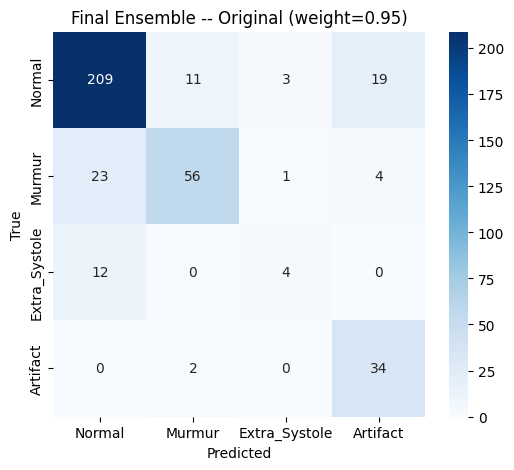


Final test accuracy: 0.8016
(Compare: YAMNet alone 0.7857, Deep CNN alone 0.7354)


In [25]:
final_cnn_weight = 1 - best_weight
final_test_probs = best_weight * probs_yamnet_test + final_cnn_weight * probs_cnn_test
final_test_preds = np.argmax(final_test_probs, axis=1)

print("=" * 60)
print(f" FINAL RESULT -- Dataset: {DATASET_LABEL}")
print(f" Ensemble weight: {best_weight} YAMNet / {final_cnn_weight:.2f} CNN (chosen via validation)")
print("=" * 60)
print(classification_report(y_test, final_test_preds, target_names=CLASSES, zero_division=0))

cm_final = confusion_matrix(y_test, final_test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title(f'Final Ensemble -- {DATASET_LABEL} (weight={best_weight})')
plt.show()

final_test_acc = np.mean(final_test_preds == y_test)
print(f"\nFinal test accuracy: {final_test_acc:.4f}")
print(f"(Compare: YAMNet alone {test_acc_yamnet:.4f}, Deep CNN alone {test_acc_deep:.4f})")

## 16. Save everything

Since the final model is an ensemble of two networks plus a chosen
weight (not one single saved file), all three pieces are saved together
-- you need all three to reproduce a prediction later.

In [26]:
import json as json_lib

model_yamnet.save("final_model_yamnet.keras")
model_deep_cnn.save("final_model_deep_cnn.keras")

ensemble_config = {
    "dataset_label": DATASET_LABEL,
    "yamnet_weight": best_weight,
    "cnn_weight": final_cnn_weight,
    "classes": CLASSES,
    "final_test_accuracy": float(final_test_acc),
}
with open("final_ensemble_config.json", "w") as f:
    json_lib.dump(ensemble_config, f, indent=2)

print("Saved: final_model_yamnet.keras, final_model_deep_cnn.keras, final_ensemble_config.json")
print(ensemble_config)

# IMMEDIATELY copy to Drive -- Colab session storage is wiped on any
# disconnect, so this happens automatically right after saving, not as
# a separate step you might forget or delay.

Saved: final_model_yamnet.keras, final_model_deep_cnn.keras, final_ensemble_config.json
{'dataset_label': 'Original', 'yamnet_weight': 0.95, 'cnn_weight': 0.050000000000000044, 'classes': ['Normal', 'Murmur', 'Extra_Systole', 'Artifact'], 'final_test_accuracy': 0.8015873015873016}


In [27]:
import shutil
drive_folder = "/content/drive/MyDrive/heart_project_finalog2"
os.makedirs(drive_folder, exist_ok=True)

for fname in ["final_model_yamnet.keras", "final_model_deep_cnn.keras", "final_ensemble_config.json"]:
    shutil.copy(fname, os.path.join(drive_folder, fname))

print("Copied to Drive:", os.listdir(drive_folder))

# To use later, from Drive:
# import tensorflow_hub as hub
# yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')
# model_yamnet = tf.keras.models.load_model("/content/drive/MyDrive/heart_project_final/final_model_yamnet.keras")
# model_deep_cnn = tf.keras.models.load_model("/content/drive/MyDrive/heart_project_final/final_model_deep_cnn.keras")
# with open("/content/drive/MyDrive/heart_project_final/final_ensemble_config.json") as f:
#     config = json_lib.load(f)
# final_probs = config["yamnet_weight"] * yamnet_probs + config["cnn_weight"] * cnn_probs

Copied to Drive: ['final_model_yamnet.keras', 'final_model_deep_cnn.keras', 'final_ensemble_config.json']


## 17. (Optional, expensive) Grouped 5-Fold Cross-Validation

Runs the full architecture 5 times, each time holding out a different
1/5 of source recordings as test, grouped so no recording's chunks
leak across folds -- gives a proper cross-validated estimate instead of
one split's luck. This retrains both models 5 times: expect this to take
roughly 5x as long as a single run above. Only run this once you're
confident in the architecture and want a final, more rigorous number for
your report.

In [ ]:
import re
from sklearn.model_selection import KFold

def get_source_id(chunk_filename):
    return re.sub(r'_chunk\d+\.wav$', '', chunk_filename)

def gather_all_chunks_by_class():
    """Pools train+val+test back together, grouped by source recording,
    so folds can be built fresh from the full pool."""
    all_files = {cls: [] for cls in CLASSES}
    for split in ["train", "val", "test"]:
        for cls in CLASSES:
            class_dir = os.path.join("split_dataset", split, cls)
            if not os.path.isdir(class_dir):
                continue
            for f in os.listdir(class_dir):
                if f.endswith(".wav"):
                    all_files[cls].append(os.path.join(class_dir, f))
    return all_files

all_files_by_class = gather_all_chunks_by_class()
for cls in CLASSES:
    n_files = len(all_files_by_class[cls])
    n_sources = len(set(get_source_id(os.path.basename(f)) for f in all_files_by_class[cls]))
    print(f"{cls}: {n_files} chunks from {n_sources} source recordings")

Normal: 1319 chunks from 331 source recordings
Murmur: 606 chunks from 125 source recordings
Extra_Systole: 470 chunks from 46 source recordings
Artifact: 240 chunks from 40 source recordings


In [ ]:
N_FOLDS = 5
RANDOM_SEED_CV = 42

# Build source-id -> list of chunk filepaths, per class
source_groups_by_class = {}
for cls in CLASSES:
    groups = {}
    for filepath in all_files_by_class[cls]:
        sid = get_source_id(os.path.basename(filepath))
        groups.setdefault(sid, []).append(filepath)
    source_groups_by_class[cls] = groups

fold_results = []

for fold_idx in range(N_FOLDS):
    print(f"\n{'='*60}\n FOLD {fold_idx+1}/{N_FOLDS}\n{'='*60}")

    fold_train_files, fold_test_files = [], []
    fold_train_labels, fold_test_labels = [], []

    for class_idx, cls in enumerate(CLASSES):
        source_ids = sorted(source_groups_by_class[cls].keys())
        kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED_CV)
        splits = list(kf.split(source_ids))
        train_idx, test_idx = splits[fold_idx]

        train_sources = [source_ids[i] for i in train_idx]
        test_sources = [source_ids[i] for i in test_idx]

        for sid in train_sources:
            for fp in source_groups_by_class[cls][sid]:
                fold_train_files.append(fp)
                fold_train_labels.append(class_idx)
        for sid in test_sources:
            for fp in source_groups_by_class[cls][sid]:
                fold_test_files.append(fp)
                fold_test_labels.append(class_idx)

    print(f"Fold {fold_idx+1}: {len(fold_train_files)} train chunks, {len(fold_test_files)} test chunks")

    # Build spectrogram arrays for this fold's test set
    X_fold_test = np.array([wav_to_logmel(fp) for fp in fold_test_files], dtype=np.float32)[..., np.newaxis]
    y_fold_test = np.array(fold_test_labels, dtype=np.int64)

    # Build YAMNet embeddings for this fold's test set
    X_fold_test_yamnet = []
    for fp in fold_test_files:
        audio = load_and_filter(fp, TARGET_SR)
        audio = load_fixed_length(audio, is_array=True)
        waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
        _, emb, _ = yamnet_model(waveform)
        X_fold_test_yamnet.append(tf.reduce_mean(emb, axis=0).numpy())
    X_fold_test_yamnet = np.array(X_fold_test_yamnet, dtype=np.float32)

    # A lightweight held-out slice of the fold's own train files, for this fold's weight selection
    val_cutoff = int(0.85 * len(fold_train_files))
    combined = list(zip(fold_train_files, fold_train_labels))
    np.random.RandomState(RANDOM_SEED_CV).shuffle(combined)
    fold_train_files_sub = [c[0] for c in combined[:val_cutoff]]
    fold_train_labels_sub = [c[1] for c in combined[:val_cutoff]]
    fold_val_files = [c[0] for c in combined[val_cutoff:]]
    fold_val_labels = [c[1] for c in combined[val_cutoff:]]

    class FoldSequence(Sequence):
        def __init__(self, files_, labels_, batch_size=32, augment=True):
            self.files = files_
            self.labels = labels_
            self.batch_size = batch_size
            self.augment = augment
            self.noise_pool = load_noise_pool() if augment else None
        def __len__(self):
            return int(np.ceil(len(self.files) / self.batch_size))
        def on_epoch_end(self):
            pass
        def __getitem__(self, idx):
            batch_files = self.files[idx*self.batch_size:(idx+1)*self.batch_size]
            batch_labels = self.labels[idx*self.batch_size:(idx+1)*self.batch_size]
            X, y = [], []
            for fp, label in zip(batch_files, batch_labels):
                audio = load_and_filter(fp, TARGET_SR)
                audio = load_fixed_length(audio, is_array=True)
                if self.augment:
                    audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                    audio = load_fixed_length(audio, is_array=True)
                spec = audio_to_logmel(audio, TARGET_SR)
                X.append(spec)
                y.append(label)
            return np.array(X, dtype=np.float32)[..., np.newaxis], np.array(y, dtype=np.int64)

    class FoldYamnetSequence(Sequence):
        def __init__(self, files_, labels_, batch_size=32, augment=True):
            self.files = files_
            self.labels = labels_
            self.batch_size = batch_size
            self.augment = augment
            self.noise_pool = load_noise_pool() if augment else None
        def __len__(self):
            return int(np.ceil(len(self.files) / self.batch_size))
        def on_epoch_end(self):
            pass
        def __getitem__(self, idx):
            batch_files = self.files[idx*self.batch_size:(idx+1)*self.batch_size]
            batch_labels = self.labels[idx*self.batch_size:(idx+1)*self.batch_size]
            X, y = [], []
            for fp, label in zip(batch_files, batch_labels):
                audio = load_and_filter(fp, TARGET_SR)
                audio = load_fixed_length(audio, is_array=True)
                if self.augment:
                    audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                    audio = load_fixed_length(audio, is_array=True)
                waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
                _, emb, _ = yamnet_model(waveform)
                X.append(tf.reduce_mean(emb, axis=0).numpy())
                y.append(label)
            return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)

    X_fold_val_yamnet = []
    for fp in fold_val_files:
        audio = load_and_filter(fp, TARGET_SR)
        audio = load_fixed_length(audio, is_array=True)
        waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
        _, emb, _ = yamnet_model(waveform)
        X_fold_val_yamnet.append(tf.reduce_mean(emb, axis=0).numpy())
    X_fold_val_yamnet = np.array(X_fold_val_yamnet, dtype=np.float32)
    y_fold_val = np.array(fold_val_labels, dtype=np.int64)

    X_fold_val = np.array([wav_to_logmel(fp) for fp in fold_val_files], dtype=np.float32)[..., np.newaxis]

    fold_weights_yamnet = compute_class_weights()
    fold_weights_yamnet[2] *= 0.7
    fold_weights_cnn = compute_class_weights()

    m_yamnet = build_yamnet_head()
    m_yamnet.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m_yamnet.fit(
        FoldYamnetSequence(fold_train_files_sub, fold_train_labels_sub),
        validation_data=(X_fold_val_yamnet, y_fold_val),
        epochs=25,
        class_weight=fold_weights_yamnet,
        callbacks=[EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)],
        verbose=0,
    )

    m_cnn = build_deep_cnn()
    m_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m_cnn.fit(
        FoldSequence(fold_train_files_sub, fold_train_labels_sub),
        validation_data=(X_fold_val, y_fold_val),
        epochs=25,
        class_weight=fold_weights_cnn,
        callbacks=[EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)],
        verbose=0,
    )

    p_yamnet_val = m_yamnet.predict(X_fold_val_yamnet, verbose=0)
    p_cnn_val = m_cnn.predict(X_fold_val, verbose=0)
    p_yamnet_test = m_yamnet.predict(X_fold_test_yamnet, verbose=0)
    p_cnn_test = m_cnn.predict(X_fold_test, verbose=0)

    fold_best_w, fold_best_f1 = 0.5, -1
    for w in CANDIDATE_WEIGHTS:
        blend = w * p_yamnet_val + (1 - w) * p_cnn_val
        preds = np.argmax(blend, axis=1)
        rep = classification_report(y_fold_val, preds, target_names=CLASSES, output_dict=True, zero_division=0)
        f1 = rep["Extra_Systole"]["f1-score"]
        if f1 > fold_best_f1:
            fold_best_f1 = f1
            fold_best_w = w

    final_blend = fold_best_w * p_yamnet_test + (1 - fold_best_w) * p_cnn_test
    final_preds = np.argmax(final_blend, axis=1)
    fold_acc = np.mean(final_preds == y_fold_test)
    fold_report = classification_report(y_fold_test, final_preds, target_names=CLASSES, output_dict=True, zero_division=0)
    fold_es_f1 = fold_report["Extra_Systole"]["f1-score"]

    print(f"Fold {fold_idx+1} result: YAMNet weight={fold_best_w}, CNN weight={1-fold_best_w:.2f}, "
          f"accuracy={fold_acc:.4f}, Extra_Systole f1={fold_es_f1:.2f}")
    fold_results.append({"fold": fold_idx+1, "yamnet_weight": fold_best_w, "cnn_weight": round(1-fold_best_w, 2),
                         "accuracy": fold_acc, "extra_systole_f1": fold_es_f1})

print("\n" + "="*60)
print(" 5-FOLD CROSS-VALIDATION SUMMARY")
print("="*60)
accs = [r["accuracy"] for r in fold_results]
f1s = [r["extra_systole_f1"] for r in fold_results]
print(f"Accuracy: {np.mean(accs):.4f} +/- {np.std(accs):.4f}  (range {min(accs):.4f}-{max(accs):.4f})")
print(f"Extra_Systole f1: {np.mean(f1s):.4f} +/- {np.std(f1s):.4f}  (range {min(f1s):.4f}-{max(f1s):.4f})")
for r in fold_results:
    print(r)